# 04 — SBERT and Hybrid Classifiers (CV-corrected)

**Inputs:** `artifacts/train.csv`, `artifacts/test.csv`, `artifacts/metrics_tfidf.json`  
**Outputs:**
- `artifacts/train_emb.npy`, `artifacts/test_emb.npy`
- `artifacts/metrics_sbert.json`, `artifacts/metrics_hybrid.json`
- `artifacts/grid_sbert_cv.csv`, `artifacts/grid_hybrid_cv.csv`
- `artifacts/figs/fig_cm_sbert.png`, `artifacts/figs/fig_three_way_comparison.png`

**Feeds thesis:** Chapter 4.2 — Proposed Classification Results

### Methodology corrections

Same protocol as Notebook 3 — **all hyperparameters selected via 5-fold
stratified cross-validation on the training set**, test set touched once.
The earlier version selected hyperparameters by looking at the test set,
which inflated the reported scores.

**Protocol:**
1. SBERT embeddings computed and cached.
2. **GridSearchCV (5-fold CV)** for pure SBERT — select best by CV macro-F1.
3. **GridSearchCV (5-fold CV)** for hybrid — select best by CV macro-F1.
4. Baseline metrics loaded from Notebook 3 (already CV-corrected).
5. Test set evaluated **once** for each model.

Reported test metrics reflect generalisation, not selection bias.

## 1. Setup

In [1]:
import pandas as pd, numpy as np, json, time, os
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from scipy.sparse import hstack
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs('../artifacts/figs', exist_ok=True)
train = pd.read_csv('../artifacts/train.csv')
test  = pd.read_csv('../artifacts/test.csv')
print('train:', train.shape, '| test:', test.shape)
print('train pos rate:', round(train.relevant.mean(), 4))
print('test  pos rate:', round(test.relevant.mean(), 4))

c:\Users\Hp\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: (8946, 12) | test: (2800, 12)
train pos rate: 0.3473
test  pos rate: 0.3482


## 2. Generate / load Sentence-BERT embeddings

Embeddings are cached to disk; a warm run skips re-encoding (~8 min saved).

In [2]:
EMB_TRAIN = '../artifacts/train_emb.npy'
EMB_TEST  = '../artifacts/test_emb.npy'

if os.path.exists(EMB_TRAIN) and os.path.exists(EMB_TEST):
    X_train_emb = np.load(EMB_TRAIN)
    X_test_emb  = np.load(EMB_TEST)
    embed_time = 0.0
    print('Loaded cached embeddings.')
else:
    sbert = SentenceTransformer('all-MiniLM-L6-v2')
    t0 = time.time()
    X_train_emb = sbert.encode(train['sentence_text'].tolist(), batch_size=64,
                               show_progress_bar=True, convert_to_numpy=True)
    X_test_emb  = sbert.encode(test['sentence_text'].tolist(),  batch_size=64,
                               show_progress_bar=True, convert_to_numpy=True)
    embed_time = time.time() - t0
    np.save(EMB_TRAIN, X_train_emb); np.save(EMB_TEST, X_test_emb)
    print('Saved embeddings.')

print('embedding time:', round(embed_time, 2), 's')
print('train shape:', X_train_emb.shape, '| test shape:', X_test_emb.shape)

Loaded cached embeddings.
embedding time: 0.0 s
train shape: (8946, 384) | test shape: (2800, 384)


## 3. Pure SBERT — GridSearchCV on training set

5-fold stratified CV on `X_train_emb`. **Test set not touched.**

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- LinearSVC ---
pipe_svc = Pipeline([('clf', LinearSVC(random_state=42, max_iter=10000))])
grid_svc = {
    'clf__C':            [0.1, 0.3, 0.5, 1.0, 2.0],
    'clf__class_weight': [None, 'balanced'],
}
search_svc = GridSearchCV(
    pipe_svc, grid_svc, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True, verbose=0
)

# --- LogReg ---
pipe_log = Pipeline([('clf', LogisticRegression(max_iter=2000, solver='liblinear', random_state=42))])
grid_log = {
    'clf__C':            [0.3, 1.0, 2.0],
    'clf__class_weight': ['balanced'],
}
search_log = GridSearchCV(
    pipe_log, grid_log, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True, verbose=0
)

t0 = time.time()
search_svc.fit(X_train_emb, train['relevant'])
search_log.fit(X_train_emb, train['relevant'])
search_time = time.time() - t0

print(f'CV search time: {search_time:.1f} s')
print(f"LinearSVC — best CV macro-F1: {search_svc.best_score_:.4f}  params: {search_svc.best_params_}")
print(f"LogReg    — best CV macro-F1: {search_log.best_score_:.4f}  params: {search_log.best_params_}")

CV search time: 75.7 s
LinearSVC — best CV macro-F1: 0.7402  params: {'clf__C': 0.3, 'clf__class_weight': 'balanced'}
LogReg    — best CV macro-F1: 0.7395  params: {'clf__C': 2.0, 'clf__class_weight': 'balanced'}


## 4. SBERT CV grid (for appendix)

In [4]:
def cv_grid_df(search, family):
    df = pd.DataFrame(search.cv_results_)
    df['family'] = family
    return df[['family','params','mean_test_score','std_test_score','rank_test_score']]

grid_sbert_all = pd.concat([
    cv_grid_df(search_svc, 'LinearSVC'),
    cv_grid_df(search_log, 'LogReg'),
], ignore_index=True).sort_values('rank_test_score').reset_index(drop=True)
grid_sbert_all['mean_test_score'] = grid_sbert_all['mean_test_score'].round(4)
grid_sbert_all['std_test_score']  = grid_sbert_all['std_test_score'].round(4)
print(grid_sbert_all.to_string(index=False))
grid_sbert_all.to_csv('../artifacts/grid_sbert_cv.csv', index=False)
print('saved -> artifacts/grid_sbert_cv.csv')

   family                                           params  mean_test_score  std_test_score  rank_test_score
LinearSVC {'clf__C': 0.3, 'clf__class_weight': 'balanced'}           0.7402          0.0165                1
   LogReg {'clf__C': 2.0, 'clf__class_weight': 'balanced'}           0.7395          0.0142                1
LinearSVC {'clf__C': 0.5, 'clf__class_weight': 'balanced'}           0.7396          0.0156                2
   LogReg {'clf__C': 1.0, 'clf__class_weight': 'balanced'}           0.7380          0.0146                2
LinearSVC {'clf__C': 1.0, 'clf__class_weight': 'balanced'}           0.7386          0.0146                3
   LogReg {'clf__C': 0.3, 'clf__class_weight': 'balanced'}           0.7325          0.0137                3
LinearSVC       {'clf__C': 1.0, 'clf__class_weight': None}           0.7378          0.0121                4
LinearSVC       {'clf__C': 2.0, 'clf__class_weight': None}           0.7375          0.0129                5
LinearSVC       {'c

## 5. Select best pure-SBERT model, evaluate on test once

In [5]:
if search_svc.best_score_ >= search_log.best_score_:
    best_sbert_search = search_svc
    best_sbert_family = 'LinearSVC'
else:
    best_sbert_search = search_log
    best_sbert_family = 'LogReg'

clf_sbert = best_sbert_search.best_estimator_

t0 = time.time()
pred_sbert = clf_sbert.predict(X_test_emb)
infer_time = time.time() - t0

m_sbert = {
    'model': f"SBERT + {best_sbert_family}",
    'embedding_model': 'all-MiniLM-L6-v2',
    'selection_strategy': '5-fold StratifiedKFold on training set',
    'cv_macro_f1':  float(best_sbert_search.best_score_),
    'accuracy':     float(accuracy_score(test['relevant'], pred_sbert)),
    'precision':    float(precision_score(test['relevant'], pred_sbert, zero_division=0)),
    'recall':       float(recall_score(test['relevant'], pred_sbert, zero_division=0)),
    'macro_f1':     float(f1_score(test['relevant'], pred_sbert, average='macro', zero_division=0)),
    'weighted_f1':  float(f1_score(test['relevant'], pred_sbert, average='weighted', zero_division=0)),
    'embed_time_s': round(embed_time, 2),
    'infer_time_s': round(infer_time, 4),
    'hyperparams':  best_sbert_search.best_params_,
}

print(json.dumps(m_sbert, indent=2))
print('\nClassification report (test):\n')
print(classification_report(test['relevant'], pred_sbert, digits=4))
json.dump(m_sbert, open('../artifacts/metrics_sbert.json','w'), indent=2)

{
  "model": "SBERT + LinearSVC",
  "embedding_model": "all-MiniLM-L6-v2",
  "selection_strategy": "5-fold StratifiedKFold on training set",
  "cv_macro_f1": 0.7402331498433578,
  "accuracy": 0.7267857142857143,
  "precision": 0.5880872483221476,
  "recall": 0.718974358974359,
  "macro_f1": 0.712070109718494,
  "weighted_f1": 0.7318304002116018,
  "embed_time_s": 0.0,
  "infer_time_s": 0.055,
  "hyperparams": {
    "clf__C": 0.3,
    "clf__class_weight": "balanced"
  }
}

Classification report (test):

              precision    recall  f1-score   support

           0     0.8296    0.7310    0.7772      1825
           1     0.5881    0.7190    0.6470       975

    accuracy                         0.7268      2800
   macro avg     0.7088    0.7250    0.7121      2800
weighted avg     0.7455    0.7268    0.7318      2800



## 6. Build hybrid features

TF-IDF fit on **train only**; SBERT embeddings L2-normalized; concatenated via `hstack`.

In [6]:
vec_h = TfidfVectorizer(max_features=10000, ngram_range=(1,2), sublinear_tf=True)
X_train_tfidf = vec_h.fit_transform(train['sentence_text'])
X_test_tfidf  = vec_h.transform(test['sentence_text'])

X_train_emb_n = normalize(X_train_emb)
X_test_emb_n  = normalize(X_test_emb)

X_train_hybrid = hstack([X_train_tfidf, X_train_emb_n]).tocsr()
X_test_hybrid  = hstack([X_test_tfidf,  X_test_emb_n]).tocsr()
print('hybrid train:', X_train_hybrid.shape)
print('hybrid test :', X_test_hybrid.shape)

hybrid train: (8946, 10384)
hybrid test : (2800, 10384)


## 7. Hybrid — GridSearchCV on training set

5-fold stratified CV on `X_train_hybrid`. **Test set not touched.**

In [7]:
pipe_h_log = Pipeline([
    ('clf', LogisticRegression(max_iter=2000, solver='liblinear', random_state=42))
])
grid_h_log = {
    'clf__C':            [0.5, 1.0, 2.0],
    'clf__class_weight': ['balanced'],
}
search_h_log = GridSearchCV(
    pipe_h_log, grid_h_log, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True, verbose=0
)

pipe_h_svc = Pipeline([
    ('clf', LinearSVC(random_state=42, max_iter=10000))
])
grid_h_svc = {
    'clf__C':            [0.3, 0.5, 1.0, 2.0],
    'clf__class_weight': [None, 'balanced'],
}
search_h_svc = GridSearchCV(
    pipe_h_svc, grid_h_svc, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True, verbose=0
)

t0 = time.time()
search_h_log.fit(X_train_hybrid, train['relevant'])
search_h_svc.fit(X_train_hybrid, train['relevant'])
hybrid_search_time = time.time() - t0

print(f'CV search time: {hybrid_search_time:.1f} s')
print(f"LogReg    — best CV macro-F1: {search_h_log.best_score_:.4f}  params: {search_h_log.best_params_}")
print(f"LinearSVC — best CV macro-F1: {search_h_svc.best_score_:.4f}  params: {search_h_svc.best_params_}")

CV search time: 44.7 s
LogReg    — best CV macro-F1: 0.7822  params: {'clf__C': 2.0, 'clf__class_weight': 'balanced'}
LinearSVC — best CV macro-F1: 0.7827  params: {'clf__C': 0.3, 'clf__class_weight': 'balanced'}


## 8. Hybrid CV grid (for appendix)

In [8]:
grid_hybrid_all = pd.concat([
    cv_grid_df(search_h_log, 'LogReg'),
    cv_grid_df(search_h_svc, 'LinearSVC'),
], ignore_index=True).sort_values('rank_test_score').reset_index(drop=True)
grid_hybrid_all['mean_test_score'] = grid_hybrid_all['mean_test_score'].round(4)
grid_hybrid_all['std_test_score']  = grid_hybrid_all['std_test_score'].round(4)
print(grid_hybrid_all.to_string(index=False))
grid_hybrid_all.to_csv('../artifacts/grid_hybrid_cv.csv', index=False)
print('saved -> artifacts/grid_hybrid_cv.csv')

   family                                           params  mean_test_score  std_test_score  rank_test_score
   LogReg {'clf__C': 2.0, 'clf__class_weight': 'balanced'}           0.7822          0.0151                1
LinearSVC {'clf__C': 0.3, 'clf__class_weight': 'balanced'}           0.7827          0.0180                1
   LogReg {'clf__C': 1.0, 'clf__class_weight': 'balanced'}           0.7788          0.0124                2
LinearSVC {'clf__C': 0.5, 'clf__class_weight': 'balanced'}           0.7785          0.0188                2
   LogReg {'clf__C': 0.5, 'clf__class_weight': 'balanced'}           0.7689          0.0123                3
LinearSVC       {'clf__C': 0.3, 'clf__class_weight': None}           0.7772          0.0167                3
LinearSVC {'clf__C': 1.0, 'clf__class_weight': 'balanced'}           0.7755          0.0169                4
LinearSVC       {'clf__C': 0.5, 'clf__class_weight': None}           0.7744          0.0171                5
LinearSVC       {'c

## 9. Select best hybrid model, evaluate on test once

In [9]:
if search_h_log.best_score_ >= search_h_svc.best_score_:
    best_hybrid_search = search_h_log
    best_hybrid_family = 'LogReg'
else:
    best_hybrid_search = search_h_svc
    best_hybrid_family = 'LinearSVC'

clf_hybrid = best_hybrid_search.best_estimator_
pred_hybrid = clf_hybrid.predict(X_test_hybrid)

m_hybrid = {
    'model': f"Hybrid (TF-IDF + SBERT) + {best_hybrid_family}",
    'selection_strategy': '5-fold StratifiedKFold on training set',
    'cv_macro_f1':  float(best_hybrid_search.best_score_),
    'accuracy':     float(accuracy_score(test['relevant'], pred_hybrid)),
    'precision':    float(precision_score(test['relevant'], pred_hybrid, zero_division=0)),
    'recall':       float(recall_score(test['relevant'], pred_hybrid, zero_division=0)),
    'macro_f1':     float(f1_score(test['relevant'], pred_hybrid, average='macro', zero_division=0)),
    'weighted_f1':  float(f1_score(test['relevant'], pred_hybrid, average='weighted', zero_division=0)),
    'hyperparams':  best_hybrid_search.best_params_,
}

print(json.dumps(m_hybrid, indent=2))
print('\nClassification report (test):\n')
print(classification_report(test['relevant'], pred_hybrid, digits=4))
json.dump(m_hybrid, open('../artifacts/metrics_hybrid.json','w'), indent=2)

{
  "model": "Hybrid (TF-IDF + SBERT) + LinearSVC",
  "selection_strategy": "5-fold StratifiedKFold on training set",
  "cv_macro_f1": 0.7827361398957805,
  "accuracy": 0.7675,
  "precision": 0.6575875486381323,
  "recall": 0.6933333333333334,
  "macro_f1": 0.7470016826303497,
  "weighted_f1": 0.7688631252454096,
  "hyperparams": {
    "clf__C": 0.3,
    "clf__class_weight": "balanced"
  }
}

Classification report (test):

              precision    recall  f1-score   support

           0     0.8313    0.8071    0.8190      1825
           1     0.6576    0.6933    0.6750       975

    accuracy                         0.7675      2800
   macro avg     0.7444    0.7502    0.7470      2800
weighted avg     0.7708    0.7675    0.7689      2800



## 10. Three-way comparison

Baseline metrics loaded from Notebook 3 (already CV-corrected).
Generalisation gap = `cv_macro_f1 − macro_f1` per model.

In [10]:
with open('../artifacts/metrics_tfidf.json') as f:
    m_base = json.load(f)

comp = pd.DataFrame([m_base, m_sbert, m_hybrid])[[
    'model','cv_macro_f1','macro_f1','accuracy','precision','recall','weighted_f1'
]].round(4)
comp['gap'] = (comp['cv_macro_f1'] - comp['macro_f1']).round(4)
print(comp.to_string(index=False))

print('\nMacro-F1 deltas vs baseline (test):')
print(f"  SBERT  : {m_sbert['macro_f1'] - m_base['macro_f1']:+.4f}")
print(f"  Hybrid : {m_hybrid['macro_f1'] - m_base['macro_f1']:+.4f}")

                                model  cv_macro_f1  macro_f1  accuracy  precision  recall  weighted_f1    gap
LogReg (C=2.0, class_weight=balanced)       0.7748    0.7444    0.7621     0.6421  0.7159       0.7648 0.0304
                    SBERT + LinearSVC       0.7402    0.7121    0.7268     0.5881  0.7190       0.7318 0.0281
  Hybrid (TF-IDF + SBERT) + LinearSVC       0.7827    0.7470    0.7675     0.6576  0.6933       0.7689 0.0357

Macro-F1 deltas vs baseline (test):
  SBERT  : -0.0323
  Hybrid : +0.0026


## 11. Three-way comparison figure

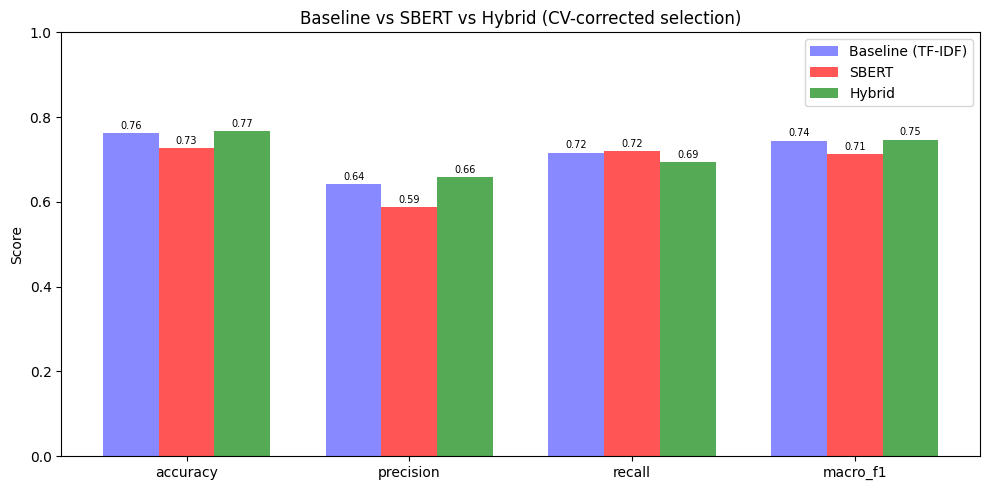

saved -> artifacts/figs/fig_three_way_comparison.png


In [11]:
metrics_cols = ['accuracy','precision','recall','macro_f1']
x = np.arange(len(metrics_cols))
w = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, (label, mrow, color) in enumerate([
    ('Baseline (TF-IDF)', m_base, '#8888ff'),
    ('SBERT',             m_sbert, '#ff5555'),
    ('Hybrid',            m_hybrid, '#55aa55')]):
    vals = [mrow[k] for k in metrics_cols]
    ax.bar(x + (i-1)*w, vals, w, label=label, color=color)
    for j, v in enumerate(vals):
        ax.text(j + (i-1)*w, v + 0.01, f'{v:.2f}', ha='center', fontsize=7)

ax.set_xticks(x); ax.set_xticklabels(metrics_cols)
ax.set_ylim(0, 1); ax.set_ylabel('Score')
ax.set_title('Baseline vs SBERT vs Hybrid (CV-corrected selection)')
ax.legend()
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_three_way_comparison.png')
plt.show()
print('saved -> artifacts/figs/fig_three_way_comparison.png')

## 12. Confusion matrices (test set)

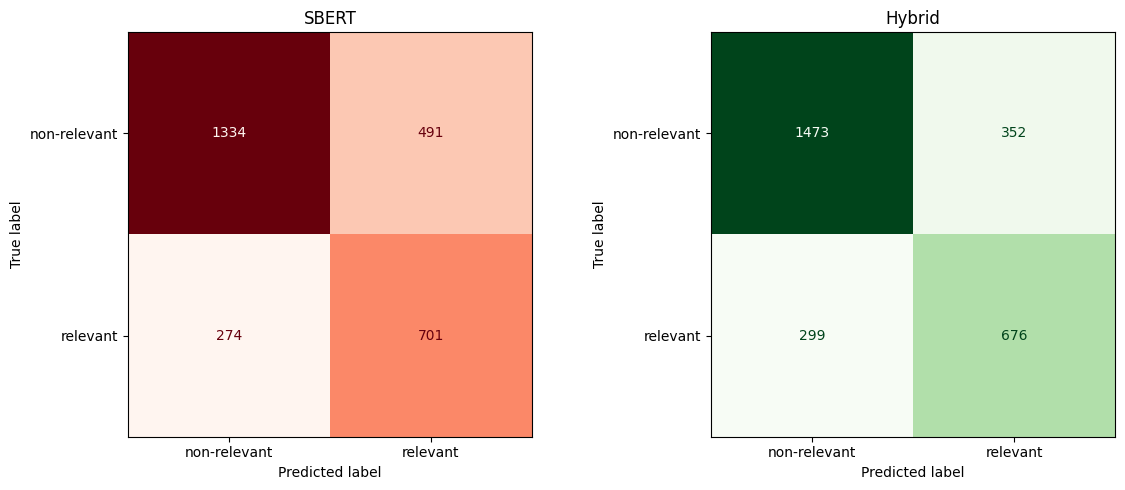

saved -> artifacts/figs/fig_cm_sbert.png, fig_cm_hybrid.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, title, cmap in [
    (axes[0], pred_sbert,  'SBERT',  'Reds'),
    (axes[1], pred_hybrid, 'Hybrid', 'Greens')]:
    cm = confusion_matrix(test['relevant'], pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['non-relevant','relevant']).plot(ax=ax, cmap=cmap, values_format='d', colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig('../artifacts/figs/fig_cm_sbert.png')
plt.savefig('../artifacts/figs/fig_cm_hybrid.png')
plt.show()
print('saved -> artifacts/figs/fig_cm_sbert.png, fig_cm_hybrid.png')

## 13. Classification summary

**Note the CV-vs-test gap** column — if |gap| < 0.03, generalisation is good.

In [13]:
print('=' * 88)
print(f"{'CLASSIFICATION — CV-CORRECTED THREE-WAY SUMMARY':^88s}")
print('=' * 88)
print(f"{'Model':<22s}{'CV F1':>8s}{'Test F1':>10s}{'Gap':>8s}{'Acc':>8s}{'Prec':>8s}{'Rec':>8s}")
print('-' * 88)
for label, mrow in [('Baseline (TF-IDF)', m_base),
                    ('SBERT',             m_sbert),
                    ('Hybrid',            m_hybrid)]:
    gap = mrow.get('cv_macro_f1', 0) - mrow['macro_f1']
    print(f"{label:<22s}"
          f"{mrow.get('cv_macro_f1', 0):>8.4f}"
          f"{mrow['macro_f1']:>10.4f}"
          f"{gap:>+8.4f}"
          f"{mrow['accuracy']:>8.4f}"
          f"{mrow['precision']:>8.4f}"
          f"{mrow['recall']:>8.4f}")
print('=' * 88)
print('\nMethodology note for Chapter 4.2:')
print('Hyperparameters selected via 5-fold stratified CV on the training set.')
print('Test set evaluated exactly once per model. Reported test metrics')
print('reflect generalisation performance, not selection bias.')
print('CV grids saved to artifacts/grid_sbert_cv.csv and grid_hybrid_cv.csv.')

                    CLASSIFICATION — CV-CORRECTED THREE-WAY SUMMARY                     
Model                    CV F1   Test F1     Gap     Acc    Prec     Rec
----------------------------------------------------------------------------------------
Baseline (TF-IDF)       0.7748    0.7444 +0.0304  0.7621  0.6421  0.7159
SBERT                   0.7402    0.7121 +0.0282  0.7268  0.5881  0.7190
Hybrid                  0.7827    0.7470 +0.0357  0.7675  0.6576  0.6933

Methodology note for Chapter 4.2:
Hyperparameters selected via 5-fold stratified CV on the training set.
Test set evaluated exactly once per model. Reported test metrics
reflect generalisation performance, not selection bias.
CV grids saved to artifacts/grid_sbert_cv.csv and grid_hybrid_cv.csv.
